# Lecture 25 · Assignment: worked solution (instructor copy)

**Data Bases and Data Wrangling Series · NoSQL Databases for Bioinformatics**

This notebook solves the assignment at the bottom of [`workbook.ipynb`](workbook.ipynb) **step by step**, with the *reasoning* written next to every line of code, so that you can walk through it with the students.

> 🔒 **Keep it away from students until the assignment is graded.** The student notebook only has the *starter code* with `TODO`s; this file contains the answers.

## The assignment (as given to the students)

| | Task | Weight |
|:-:|---|:-:|
| **1** | Fetch `assignment.vcf` from `public.example`, **slice** it (chromosomes **22** and **7**, positions **10 Mb – 60 Mb**), process it with `parse_vcf`, **insert** it into `student_db.assignment_variants` | 2% |
| **2** | Query that collection: **(a)** variants per chromosome, **(b)** QUAL distribution (`$bucket`), **(c)** distribution of the number of ALT alleles (`$size` of `alt`). One DataFrame and one plot for each | 3% |

## Suggested way to present it

1. *Task 1* (8 min): look at the raw data → decide what "slice" means → filter → insert → **verify**. Stress the verification step.
2. *Task 2* (10 min): one pipeline per question. For each, ask the class *"what should the numbers add up to?"* **before** running it; the consistency checks at the end of the notebook answer that question.
3. *Wrap-up* (2 min): the "common mistakes" table at the end.

The data are **synthetic and generated with a fixed random seed**, so every number below is the same on every laptop.

## Contents

| Section | |
|---|---|
| [0 · Setup](#0--setup-same-cells-as-in-the-workbook) | connection and the helper functions the workbook already defined |
| [Task 1](#task-1--fetch-slice-process-insert-2) | fetch → slice → insert → verify |
| [Task 2](#task-2--statistics-with-aggregation-pipelines-3) | (a) per chromosome · (b) QUAL histogram · (c) ALT alleles |
| [Self-check](#self-check-the-cell-the-students-run) | the cell the students run |
| [Answer key](#answer-key) | the correct numbers, discussion questions, common mistakes |

---
## 0 · Setup (same cells as in the workbook)

The assignment starts from the state the workbook leaves behind: a connection (`client`, `public`, `student_db`) and the helper functions `parse_vcf()` and `agg()`. Because this notebook must run on its own, the cell below **repeats** them (the code is copied from Sections 0, 4.4 and 8 of the workbook; nothing new here).

*Teaching tip: you can skip this cell when presenting in class, with the workbook open in the same Jupyter session.*

In [1]:
import io, os
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
import vcfpy
from pymongo import ASCENDING, MongoClient

pd.set_option("display.width", 160)

# ---- connection (identical to the workbook; MONGO_PORT lets you use a non-default port) -----------------------
MONGO_HOST = os.getenv("MONGO_HOST", "localhost")
MONGO_PORT = os.getenv("MONGO_PORT", "27017")
STUDENT_URI = os.getenv("MONGO_URI", f"mongodb://student:student_password@{MONGO_HOST}:{MONGO_PORT}/?authSource=admin")
ADMIN_URI = os.getenv("MONGO_ADMIN_URI", f"mongodb://admin:workshop_admin@{MONGO_HOST}:{MONGO_PORT}/?authSource=admin")

client = MongoClient(STUDENT_URI, serverSelectionTimeoutMS=5000)
client.admin.command("ping")
public, student_db = client["public"], client["student_db"]

# the assignment data live in public.example: load the shared database if this server has never seen it
if "example" not in public.list_collection_names():
    from seed_public_db import seed_public
    seed_public(ADMIN_URI)

# ---- helper 1: VCF text -> list of MongoDB documents (workbook Section 4.4) -------------------------------------------
def classify(ref, alts):
    if all(len(ref) == 1 and len(a) == 1 for a in alts): return "SNV"
    if all(len(a) > len(ref) for a in alts): return "INS"
    if all(len(a) < len(ref) for a in alts): return "DEL"
    return "OTHER"

def zygosity(gt_alleles):
    if None in gt_alleles: return "missing"
    if all(a == 0 for a in gt_alleles): return "hom_ref"
    if len(set(gt_alleles)) == 1: return "hom_alt"
    return "het"

def record_to_doc(rec):
    alts = [str(a.value) for a in rec.ALT]
    return {"chrom": rec.CHROM, "pos": rec.POS, "id": rec.ID[0] if rec.ID else None, "ref": rec.REF, "alt": alts,
            "type": classify(rec.REF, alts), "qual": float(rec.QUAL) if rec.QUAL is not None else None,
            "filter": ";".join(rec.FILTER) if rec.FILTER else None, "info": dict(rec.INFO),
            "calls": [{"sample": c.sample, "gt": c.data.get("GT"), "zygosity": zygosity(c.gt_alleles),
                       "dp": c.data.get("DP"), "gq": c.data.get("GQ")} for c in rec.calls]}

def parse_vcf(text):
    return [record_to_doc(rec) for rec in vcfpy.Reader(io.StringIO(text))]

# ---- helper 2: run an aggregation pipeline and return a DataFrame (workbook Section 8.1) --------------------------
def agg(pipeline, collection):
    return pd.DataFrame(collection.aggregate(pipeline))

print("Ready: connected to MongoDB", client.server_info()["version"], "as the student account")

Ready: connected to MongoDB 7.0.45 as the student account


---
## Task 1 · Fetch, slice, process, insert (2%)

### 1.1 What is being asked? Break it into four verbs

| verb | meaning here | tool |
|---|---|---|
| **fetch** | get the VCF *text* out of `public.example` | `find_one({"_id": "assignment.vcf"})` |
| **process** | turn every VCF line into a document | `parse_vcf()` (given) |
| **slice** | keep only the variants **inside a region** | a filter on `chrom` and `pos` |
| **insert** | store the result in **your own** database | `insert_many()` into `student_db.assignment_variants` |

> **What is a "slice"?** A *region* of the genome, written `chrom:start-end`. The command-line equivalent is
> `bcftools view -r 22:10000000-60000000,7:10000000-60000000 assignment.vcf`. Both ends are **inclusive** and positions are **1-based** (that is how VCF numbers them).

### 1.2 Fetch, and look before you filter

Always look at the data **before** transforming it: how big is it, what does it contain? Here we parse *everything* once and count the variants per contig.

In [2]:
# STEP 1: FETCH. `_id` is unique, so find_one() on it is the fastest possible look-up.
assignment_text = public["example"].find_one({"_id": "assignment.vcf"})["content"]
print(f"assignment.vcf: {len(assignment_text.splitlines())} lines, {len(assignment_text):,} characters\n")

# STEP 2: PROCESS. parse_vcf() = vcfpy reads the text + record_to_doc() builds one document per VCF line.
all_docs = parse_vcf(assignment_text)
print("variants in the whole file:", len(all_docs))

# LOOK: how are they spread over the contigs?  (Counter = "group by and count" in plain Python)
whole_file = Counter(d["chrom"] for d in all_docs)
print("variants per chromosome (whole file):", dict(sorted(whole_file.items(), key=lambda kv: int(kv[0]))))

assignment.vcf: 818 lines, 81,343 characters

variants in the whole file: 800
variants per chromosome (whole file): {'7': 193, '12': 202, '19': 200, '22': 205}


**What to notice:** 800 variants on **four** contigs (7, 12, 19, 22), about 200 each. Chromosomes 12 and 19 must disappear in the slice, and so must everything outside 10-60 Mb on chromosomes 7 and 22.

### 1.3 Slice: keep variants inside the regions

We describe the regions as **data** (a dictionary), not as `if` statements scattered around the code. Then adding a third region means editing one line.

*Reasoning about the condition:* a variant is kept if **(i)** its chromosome is one of the wanted ones **and** **(ii)** its position lies between that chromosome's start and end, **inclusive**.

In [3]:
# chromosome -> (start, end), both INCLUSIVE and 1-based, exactly like `bcftools view -r`
REGIONS = {"22": (10_000_000, 60_000_000), "7": (10_000_000, 60_000_000)}

def in_region(doc):
    """True if the variant lies inside one of the wanted regions."""
    if doc["chrom"] not in REGIONS:                  # (i) wrong chromosome -> drop
        return False
    start, end = REGIONS[doc["chrom"]]
    return start <= doc["pos"] <= end                # (ii) chained comparison = start <= pos AND pos <= end

assignment_docs = [d for d in all_docs if in_region(d)]       # <- the "slice"

# Before / after table: always show what a filter did.
slice_summary = pd.DataFrame({"whole file": whole_file, "after slicing": Counter(d["chrom"] for d in assignment_docs)}).fillna(0).astype(int)
slice_summary.index.name = "chrom"
display(slice_summary.loc[sorted(slice_summary.index, key=int)])
print("kept", len(assignment_docs), "of", len(all_docs), "variants")

# EDGE CHECK: the riskiest variants of any slice are the ones close to the edges. What did our filter decide about them?
for d in all_docs:
    if d["chrom"] in REGIONS and min(abs(d["pos"] - edge) for edge in (10_000_000, 60_000_000)) < 200_000:
        print(f"  chr{d['chrom']}:{d['pos']:,}  ->", "kept" if in_region(d) else "DROPPED (outside the window)")

,whole file,after slicing
chrom,,
7,193,60
12,202,0
19,200,0
22,205,166


kept 226 of 800 variants
  chr7:9,911,030  -> DROPPED (outside the window)
  chr22:10,147,169  -> kept


**What to notice, and a good question for the class:** chromosomes 7 and 22 both had about 200 variants in the file, yet the slice keeps **166 on chr22 but only 60 on chr7**. Why?

* The synthetic variants are spread **uniformly** along each chromosome.
* **chr22 is short** (50.8 Mb): the window 10-60 Mb covers its whole length from 10 Mb on, i.e. about **80%** of it.
* **chr7 is long** (159.3 Mb): the same window covers only 50/159 ≈ **31%** of it.

The edge check above shows the filter at work: `chr7:9,911,030` lies only 89 kb *before* the window starts and is correctly dropped, while `chr22:10,147,169` just *inside* is kept. So a region's size in *base pairs* matters less than **how much of the contig it covers**. (The window's end, 60 Mb, is *beyond* the end of chr22: that is harmless, nothing is there to select.)

### 1.4 Insert, then verify

`insert_many()` sends the whole list in one go, which is much faster than a loop of `insert_one()`.
Two habits worth teaching here:

1. **`drop()` first**, so that running the cell twice does not store every variant twice (the *idempotence* idea of the workbook).
2. **Verify**: count, and look at the stored data, instead of trusting that "no error" means "correct".

In [4]:
assignment_coll = student_db["assignment_variants"]
assignment_coll.drop()                       # start clean: re-running this cell must not create duplicates

# ---- THE TODO OF TASK 1 ---------------------------------------------------------------------------------------
result = assignment_coll.insert_many(assignment_docs, ordered=False)   # ordered=False: keep going if one document fails
print("insert_many stored", len(result.inserted_ids), "documents")     # <- "print how many documents were stored"

# An index on (chromosome, position) is what region queries need (workbook Section 4.7). Cheap to add, optional here.
assignment_coll.create_index([("chrom", ASCENDING), ("pos", ASCENDING)])

# ---- VERIFY: what is REALLY in the database? -------------------------------------------------------------------
n_stored = assignment_coll.count_documents({})
print("count_documents      :", n_stored, "->", "✅ equals the list we inserted" if n_stored == len(assignment_docs) else "❌ mismatch!")

bounds = agg([{"$group": {"_id": "$chrom", "n": {"$sum": 1}, "first_pos": {"$min": "$pos"}, "last_pos": {"$max": "$pos"}}}],
             assignment_coll).rename(columns={"_id": "chrom"})
print("\nSmallest / largest position stored per chromosome (must lie inside 10,000,000 - 60,000,000):")
display(bounds)

insert_many stored 226 documents
count_documents      : 226 -> ✅ equals the list we inserted

Smallest / largest position stored per chromosome (must lie inside 10,000,000 - 60,000,000):


,chrom,n,first_pos,last_pos
0,22,166,10147169,50248100
1,7,60,11023799,59684279


**What to notice:** `first_pos` is ≥ 10,000,000 and `last_pos` ≤ 60,000,000 on both chromosomes, and only chromosomes 7 and 22 are present. That is the proof that the slice worked.

> ### 💡 Alternative: slice *inside* MongoDB
> We filtered in **Python** (after parsing) because the starter code does so, and because it is easy to read. The database can do it too, with the same inclusive bounds, using `$or` (one clause per region) and the `(chrom, pos)` index:
>
> ```python
> region_query = {"$or": [{"chrom": c, "pos": {"$gte": s, "$lte": e}} for c, (s, e) in REGIONS.items()]}
> staging.count_documents(region_query)          # 226, the same answer
> ```
> This is the better design when the file is **large** (you would load it once and slice many times). The optional cell at the very end of this notebook runs it.

---
## Task 2 · Statistics with aggregation pipelines (3%)

Every pipeline below follows the same **recipe**, which is a good thing to say out loud to the students:

1. *What is one **row of the answer**?* (one chromosome? one QUAL bin? one ALT-count?)
2. *What is the **grouping key**?* (`$chrom`, `$qual` buckets, `{"$size": "$alt"}`)
3. *What do I **compute** per group?* (here always a count: `{"$sum": 1}`)
4. Turn the result into a **DataFrame** (`agg()`), tidy it, **plot** it, then **check** that the numbers add up.

### 2(a) Number of variants per chromosome  ≈ `bcftools query -f '%CHROM\n' | sort | uniq -c`

`$group` makes **one output document per distinct value of `_id`**; `{"$sum": 1}` adds 1 for every input document of the group, i.e. it **counts**.

,chrom,n_variants
0,7,60
1,22,166


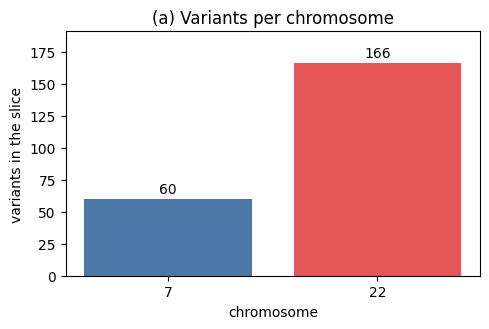

In [5]:
# ---- (a) per chromosome ---------------------------------------------------------------------------------------
per_chrom = agg([
    {"$group": {"_id": "$chrom",                    # grouping key: one output row per chromosome
                "n_variants": {"$sum": 1}}},        # count the documents of each group
], assignment_coll).rename(columns={"_id": "chrom"})

# GOTCHA: `chrom` is TEXT ("7", "22"), so a text sort would put "22" BEFORE "7". Sort numerically in pandas instead.
per_chrom = per_chrom.sort_values("chrom", key=lambda s: s.astype(int)).reset_index(drop=True)
display(per_chrom)

# ---- plot -------------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(5, 3.4))
bars = ax.bar(per_chrom["chrom"], per_chrom["n_variants"], color=["#4c78a8", "#e45756"])
ax.bar_label(bars, padding=2); ax.margins(y=0.15)         # headroom so the labels do not touch the title                                   # write the count on top of each bar
ax.set_xlabel("chromosome"); ax.set_ylabel("variants in the slice"); ax.set_title("(a) Variants per chromosome")
plt.tight_layout(); plt.show()

**Reading the result:** 166 variants on chr22, 60 on chr7: the numbers we predicted from the region coverage in 1.3. (If they did not match, we would have a bug.)

### 2(b) QUAL distribution with `$bucket`  ≈ `bcftools query -f '%QUAL\n'` + a histogram

`$bucket` puts every document into the bin `[boundaries[i], boundaries[i+1])`:

* a bin is **closed on the left, open on the right**: QUAL `30.0` goes to bin `30-40`, *not* to `20-30`;
* the **last boundary must be larger than the largest QUAL** (the largest here is 150.5, so we end at 200). A value outside all bins would be an **error** unless you give a `default` bucket;
* `$bucket` **omits empty bins**. That is fine for a table but would leave a *gap* in the plot, so we put the empty bins back (with count 0) using `reindex`.

variants that fell OUTSIDE the bins: 0 (must be 0)


,bin,n_variants
0,0-10,8
1,10-20,18
2,20-30,18
3,30-40,30
4,40-50,26
5,50-60,36
6,60-80,48
7,80-100,33
8,100-200,9


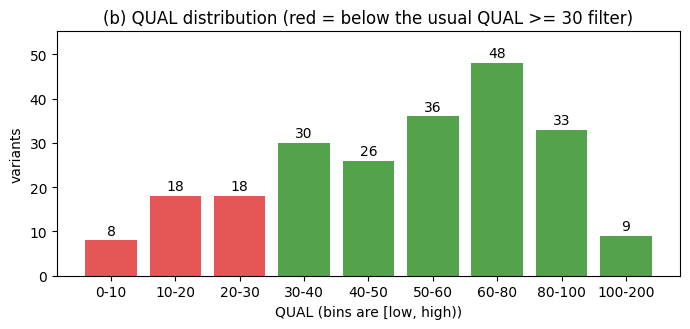

In [6]:
# ---- (b) QUAL distribution -------------------------------------------------------------------------------------
EDGES = [0, 10, 20, 30, 40, 50, 60, 80, 100, 200]      # "bins of your choice"; 30 is deliberately a boundary (see below)

raw = agg([
    {"$match": {"qual": {"$ne": None}}},                # ignore variants without a QUAL (none here, but real VCFs have "." )
    {"$bucket": {"groupBy": "$qual",                    # the value to bin
                 "boundaries": EDGES,                   # the bin edges
                 "default": "other",                    # where values outside the edges go (should stay empty!)
                 "output": {"n_variants": {"$sum": 1}}}},
], assignment_coll)

print("variants that fell OUTSIDE the bins:", int(raw.loc[raw["_id"] == "other", "n_variants"].sum()), "(must be 0)")

# `_id` of each bucket = its lower edge. Put back the empty bins, then give every bin a readable label.
qual_hist = (raw[raw["_id"] != "other"].set_index("_id")
                .reindex(EDGES[:-1], fill_value=0)                 # one row for EVERY bin, 0 where MongoDB returned nothing
                .rename_axis("lower_edge").reset_index())
qual_hist["bin"] = [f"{lo}-{hi}" for lo, hi in zip(EDGES[:-1], EDGES[1:])]
qual_hist["n_variants"] = qual_hist["n_variants"].astype(int)
display(qual_hist[["bin", "n_variants"]])

# ---- plot: colour the bins below the QUAL >= 30 threshold ------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 3.4))
colors = ["#e45756" if lo < 30 else "#54a24b" for lo in qual_hist["lower_edge"]]
bars = ax.bar(qual_hist["bin"], qual_hist["n_variants"], color=colors)
ax.bar_label(bars, padding=2); ax.margins(y=0.15)         # headroom so the labels do not touch the title
ax.set_xlabel("QUAL (bins are [low, high))"); ax.set_ylabel("variants")
ax.set_title("(b) QUAL distribution (red = below the usual QUAL >= 30 filter)")
plt.tight_layout(); plt.show()

**Reading the result** *(careful: the last three bins are wider than the others, 20/20/100 units instead of 10, so compare bar heights as **counts**, not as densities)*: two populations, as in the workbook: a **low-QUAL group** (the red bins, 44 variants) that looks like noise, and a **broad hump** of confident calls. Choosing `30` as a boundary lets us read the answer to *"how many variants would a QUAL ≥ 30 filter remove?"* directly off the histogram. We verify that claim in the consistency checks below.

### 2(c) Number of ALT alleles per variant

A VCF line can have several ALT alleles (`ALT = A,T`): a **multi-allelic** site. We stored them as the array `alt`, so *"how many ALT alleles?"* is the **length of that array**, which is what the `$size` operator returns.

The new idea: the **grouping key can be an expression**, not just a field: `"_id": {"$size": "$alt"}`.

,n_alt_alleles,n_variants
0,1,223
1,2,3


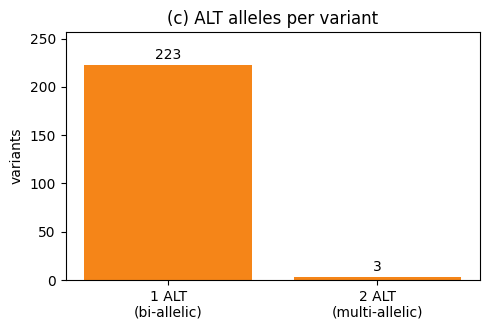

In [7]:
# ---- (c) number of ALT alleles per variant -----------------------------------------------------------------------
alt_counts = agg([
    {"$group": {"_id": {"$size": "$alt"},               # key = length of the `alt` array (an EXPRESSION, not a field)
                "n_variants": {"$sum": 1}}},
    {"$sort": {"_id": 1}},                              # 1 ALT first, then 2 ALT ... (numbers sort correctly)
], assignment_coll).rename(columns={"_id": "n_alt_alleles"})
display(alt_counts)

# ---- plot: counts are very unequal (223 vs 3), so write the numbers on the bars ------------------------------------
fig, ax = plt.subplots(figsize=(5, 3.4))
labels = [f"{n} ALT\n" + ("(bi-allelic)" if n == 1 else "(multi-allelic)") for n in alt_counts["n_alt_alleles"]]
bars = ax.bar(labels, alt_counts["n_variants"], color="#f58518")
ax.bar_label(bars, padding=2); ax.margins(y=0.15)         # headroom so the labels do not touch the title
ax.set_ylabel("variants"); ax.set_title("(c) ALT alleles per variant")
plt.tight_layout(); plt.show()

**Reading the result:** almost all sites are **bi-allelic** (223); only **3** are multi-allelic. In real call sets multi-allelic sites are also a small minority, but one that must be handled correctly (this is why we kept `alt` as an *array* in Section 4.4 instead of a single string).

### 2(d) Do the numbers add up? (consistency checks)

A result you cannot cross-check is a result you should not trust. Each check compares a number from one pipeline with a number obtained **in a different way**:

In [8]:
checks = {
    # every variant lands in exactly ONE group, so each table must sum to the number of stored documents
    "(a) per-chromosome counts add up to the collection size": per_chrom["n_variants"].sum() == n_stored,
    "(b) QUAL bins add up to the collection size":             qual_hist["n_variants"].sum() == n_stored,
    "(c) ALT-count groups add up to the collection size":      alt_counts["n_variants"].sum() == n_stored,

    # the same fact computed a SECOND way, with plain queries instead of a pipeline
    "(b) bins below 30 == variants flagged LowQual":           qual_hist.loc[qual_hist["lower_edge"] < 30, "n_variants"].sum()
                                                               == assignment_coll.count_documents({"filter": "LowQual"}),
    "(c) '2 ALT' group == variants that have a 2nd ALT":       int(alt_counts.loc[alt_counts["n_alt_alleles"] == 2, "n_variants"].sum())
                                                               == assignment_coll.count_documents({"alt.1": {"$exists": True}}),
}
for text, ok in checks.items():
    print("✅" if ok else "❌", text)
assert all(checks.values())

✅ (a) per-chromosome counts add up to the collection size
✅ (b) QUAL bins add up to the collection size
✅ (c) ALT-count groups add up to the collection size
✅ (b) bins below 30 == variants flagged LowQual
✅ (c) '2 ALT' group == variants that have a 2nd ALT


**Why the second-to-last check works:** in the generator that made this file, a variant gets the filter `LowQual` **exactly when** `QUAL < 30`. So the number of variants in the bins below 30 must equal the number of `LowQual` records. In *real* data that relation depends on the caller's filter settings, so it is a nice example of a *dataset-specific* sanity check.

---
## Self-check (the cell the students run)

Same code as at the end of the workbook. With the TODOs solved, every line must be ✅.

In [9]:
n_expected = len(assignment_docs)
n_found = assignment_coll.count_documents({})
print("Task 1:", "✅ done" if n_found == n_expected and n_found > 0 else f"❌ not yet ({n_found} documents stored, {n_expected} expected)")
if n_found:
    chroms = set(assignment_coll.distinct("chrom"))
    print("        chromosomes stored:", sorted(chroms), "->", "✅" if chroms <= set(REGIONS) else "❌ unexpected chromosomes")
for name, value in [("per chromosome", per_chrom), ("QUAL histogram", qual_hist), ("ALT-allele counts", alt_counts)]:
    print(f"Task 2 ({name}):", "✅ DataFrame with %d rows" % len(value) if isinstance(value, pd.DataFrame) and len(value) else "❌ not yet")

Task 1: ✅ done


        chromosomes stored: ['22', '7'] -> ✅
Task 2 (per chromosome): ✅ DataFrame with 2 rows
Task 2 (QUAL histogram): ✅ DataFrame with 9 rows
Task 2 (ALT-allele counts): ✅ DataFrame with 2 rows


---
## Answer key

The cell prints the final numbers from the live database, so they can never drift from the code.

In [10]:
key = pd.DataFrame([
    ("Task 1", "variants in the whole assignment.vcf",                    len(all_docs)),
    ("Task 1", "variants kept by the slice = documents in assignment_variants", n_stored),
    ("Task 2a", "variants on chr7",                                       int(per_chrom.set_index("chrom").loc["7", "n_variants"])),
    ("Task 2a", "variants on chr22",                                      int(per_chrom.set_index("chrom").loc["22", "n_variants"])),
    ("Task 2b", "variants with QUAL < 30 (the red bins)",                 int(qual_hist.loc[qual_hist["lower_edge"] < 30, "n_variants"].sum())),
    ("Task 2b", "variants with QUAL >= 30",                               int(qual_hist.loc[qual_hist["lower_edge"] >= 30, "n_variants"].sum())),
    ("Task 2c", "bi-allelic variants (1 ALT)",                            int(alt_counts.set_index("n_alt_alleles").loc[1, "n_variants"])),
    ("Task 2c", "multi-allelic variants (2 ALT)",                         int(alt_counts.set_index("n_alt_alleles").loc[2, "n_variants"])),
], columns=["task", "quantity", "correct value"])
key

,task,quantity,correct value
0,Task 1,variants in the whole assignment.vcf,800
1,Task 1,variants kept by the slice = documents in assi...,226
2,Task 2a,variants on chr7,60
3,Task 2a,variants on chr22,166
4,Task 2b,variants with QUAL < 30 (the red bins),44
5,Task 2b,variants with QUAL >= 30,182
6,Task 2c,bi-allelic variants (1 ALT),223
7,Task 2c,multi-allelic variants (2 ALT),3


### Discussion questions for the class

1. *Why does the slice keep 166 variants on chr22 but only 60 on chr7, although both contigs had about 200 in the file?* (region coverage: ≈ 80% of chr22 vs ≈ 31% of chr7)
2. *What happens to the stored data if you run the insert cell twice **without** `drop()`?* (every variant twice: counts double, the consistency checks still pass but are all wrong, a silent error!)
3. *Where would you rather slice: in Python after parsing, or in MongoDB with a query?* (Python: simple, fine for 800 records. MongoDB: scales, uses the `(chrom, pos)` index, parse once and slice many times.)
4. *Why is it safe to add `{"$match": {"qual": {"$ne": None}}}` in front of `$bucket`?* (a missing QUAL would otherwise land in the `default` bucket or raise an error)
5. *If you needed the QUAL histogram **per chromosome**, what would change?* (group by two keys: `$bucket` cannot group by chromosome, so use `$group` with `_id: {chrom: "$chrom", bin: {$floor: {$divide: ["$qual", 10]}}}`)

### Common mistakes (and how the checks reveal them)

| Mistake | Symptom | Fix |
|---|---|---|
| Forgot `drop()` before `insert_many()` | stored count is a **multiple** of the expected one | `assignment_coll.drop()` first |
| Slice with `<` instead of `<=` | one variant too few at a region edge (here the effect is invisible: no variant sits exactly on 10,000,000 or 60,000,000, which is why the check is "positions inside the bounds", not "count equals 226") | inclusive bounds, like `bcftools -r` |
| Inserted `all_docs` instead of the sliced list | chromosomes 12 and 19 present; the self-check says ❌ *unexpected chromosomes* | insert `assignment_docs` |
| Re-used the list after `insert_many()` | `DuplicateKeyError` on a second insert: `insert_many` **adds `_id` to your dicts** | build the list again with `parse_vcf()` |
| `$bucket` without `default` and a QUAL above the last boundary | `OperationFailure: ... must fall within the specified boundaries` | last boundary > max QUAL, or add `default` |
| Sorted chromosomes as text | `22` is plotted before `7` | convert to `int` for sorting |
| Plot of `$bucket` result has gaps | empty bins are **omitted** by MongoDB | `reindex` the bins with `fill_value=0` |
| Counted ALT alleles with `len()` in Python on each document | works but slow and not "an aggregation" | `{"$size": "$alt"}` inside `$group` |

### Suggested marking guide *(adapt freely: the split below is only a suggestion)*

| | Full marks if … |
|---|---|
| **Task 1 (2%)** | the VCF text is fetched from `public.example`; the slice keeps **only** chr7 and chr22 within the bounds; **226** documents are stored in `student_db.assignment_variants`; the student printed or checked the count |
| **Task 2 (3%)** | **(a)** per-chromosome counts 60 / 166 · **(b)** a `$bucket` histogram whose bins add up to 226 · **(c)** 223 bi-allelic and 3 multi-allelic · each result is a **DataFrame** *and* has a **plot** with axis labels |

---
## Optional extension · slicing *inside* MongoDB

For the students who finish early, or to show the alternative design from Section 1.4: load the **whole** file into a *staging* collection once, then slice with a query. `explain()` shows that the `(chrom, pos)` index is used.

In [11]:
staging = student_db["assignment_all"]
staging.drop()
staging.insert_many(parse_vcf(assignment_text))                    # all 800 variants, parsed once
staging.create_index([("chrom", ASCENDING), ("pos", ASCENDING)])

# one clause per region, combined with $or; same INCLUSIVE bounds as before ($gte / $lte)
region_query = {"$or": [{"chrom": c, "pos": {"$gte": s, "$lte": e}} for c, (s, e) in REGIONS.items()]}
print("variants selected by the query:", staging.count_documents(region_query), "(must equal", n_stored, ")")

plan = student_db.command({"explain": {"find": "assignment_all", "filter": region_query}, "verbosity": "executionStats"})
stats = plan["executionStats"]
print(f"documents examined: {stats['totalDocsExamined']} of 800  ->  the index was used" if stats["totalDocsExamined"] < 800 else "full scan")

staging.drop()                                                     # tidy up: this collection was only a demo

variants selected by the query: 226 (must equal 226 )
documents examined: 226 of 800  ->  the index was used


**Takeaway:** both designs give **226**. Slicing in Python is simplest; slicing in the database is what you would do for a real, large VCF, and it is exactly the situation where the index of Section 4.7 pays off.

In [12]:
client.close()